# KL robust expectations: approximation is not a bound

Finite probabilities p_i>0 and KL(q||p)<=rho. A centered log-domain exponential tilt solves the scalar KL boundary, with explicit nominal, constant-loss and saturation cases. Compare a primal SLSQP baseline, a small-radius mean-variance approximation, and an independent Bernoulli oracle. Established methods; this is not Wasserstein DRO or a calibrated confidence region.

In [1]:
import json
from pathlib import Path
r=json.loads(Path('benchmarks/results.json').read_text())
print('Predeclared gate:',r['success'])
print('Checks:',r['checks'])
print('Cases:',r['cases'])
print('SLSQP rejected:',len(r['rejected_slsqp']))
for row in r['summary']:
    print(row)

Predeclared gate: True
Checks: {'max_kl_violation': 0.0, 'max_mass_error': 5.551115123125783e-16, 'max_scaled_duality_gap': 3.677613769070831e-13, 'accepted_slsqp_fraction': 1.0, 'max_scaled_slsqp_difference': 5.793712127475385e-06, 'max_binary_oracle_error': 5.059008767460682e-13, 'rare_approximation_underestimate': 0.0026922119753416763}
Cases: 54
SLSQP rejected: 0
{'n': 3, 'cases': 18, 'slsqp_accepted': 18, 'max_gap': 3.677613769070831e-13, 'root_median_ms': 3.1147640000313004, 'slsqp_median_ms': 4.113893999999618, 'approximation_median_ms': 0.033719500038387196, 'root_peak_bytes': 4763, 'slsqp_peak_bytes': 17445}
{'n': 16, 'cases': 18, 'slsqp_accepted': 18, 'max_gap': 3.5743630277806915e-13, 'root_median_ms': 2.3151785000550262, 'slsqp_median_ms': 19.389608999972552, 'approximation_median_ms': 0.03437600003053376, 'root_peak_bytes': 5407, 'slsqp_peak_bytes': 39122}
{'n': 64, 'cases': 18, 'slsqp_accepted': 18, 'max_gap': 3.5599301284605644e-13, 'root_median_ms': 2.363429000013184, '

In [2]:
print('Two-action example (0=risky, 1=safe):')
for key,value in r['decision'].items():
    print(key,value)
assert r['decision']['mean_variance_risky_loss']<r['decision']['safe_loss']<r['decision']['exact_robust_risky_loss']

Two-action example (0=risky, 1=safe):
nominal_risky_loss 0.001
mean_variance_risky_loss 0.005469899327725402
exact_robust_risky_loss 0.008162111303067078
dual_upper 0.008162111303079533
binary_oracle 0.00816211130307954
radius 0.01
safe_loss 0.006
nominal_action 0
approximate_action 0
robust_action 1
action_labels ['risky', 'safe']
scenarios [{'scenario': 'nominal', 'true_rare_probability': 0.001, 'kl_to_nominal': 0.0, 'inside_radius': True, 'nominal_action_loss': 0.001, 'approximate_action_loss': 0.001, 'robust_action_loss': 0.006, 'best_action_loss': 0.001}, {'scenario': 'shifted', 'true_rare_probability': 0.007, 'kl_to_nominal': 0.0076394252422299575, 'inside_radius': True, 'nominal_action_loss': 0.007, 'approximate_action_loss': 0.007, 'robust_action_loss': 0.006, 'best_action_loss': 0.006}]


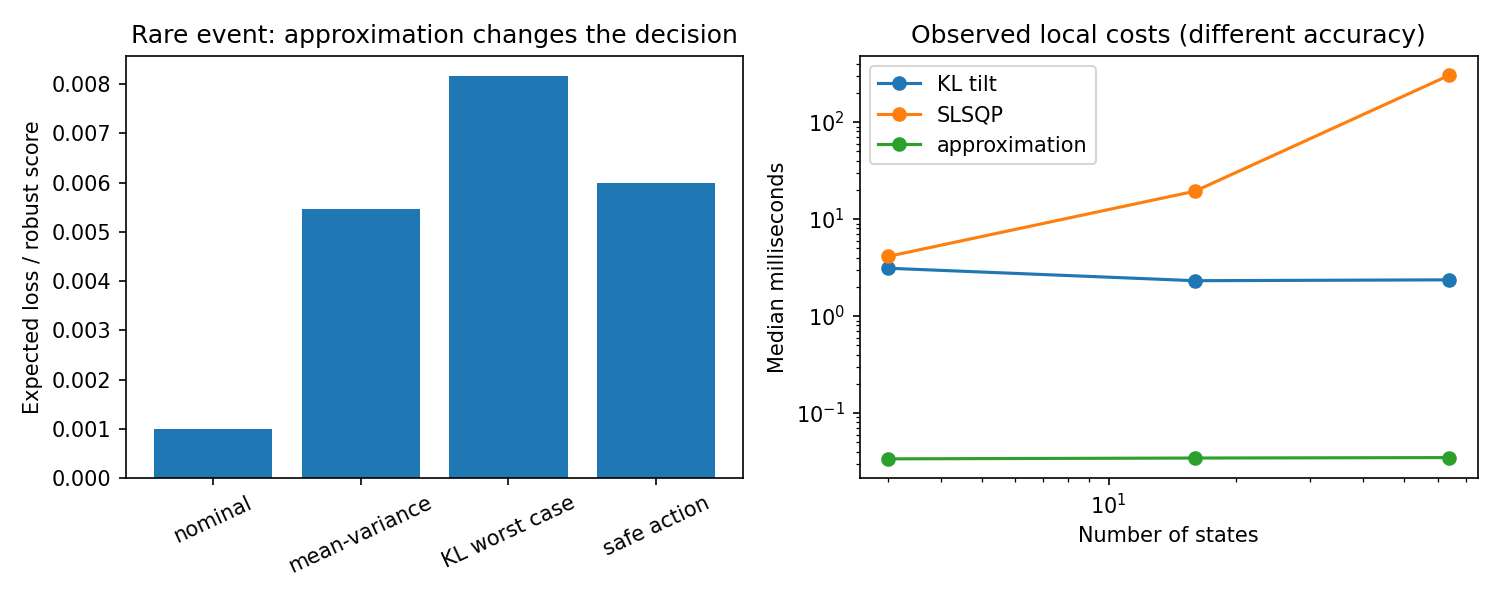

In [3]:
from IPython.display import Image,display
display(Image(filename='benchmarks/audit.png'))

In [4]:
initial=json.loads(Path('benchmarks/initial_baseline/results.json').read_text())
print('Initial baseline experiment passed?',initial['success'])
print(initial['checks'])
assert initial['success'] is False
print('Initial failed experiment retained; thresholds were not relaxed.')

Initial baseline experiment passed? False
{'max_kl_violation': 0.0, 'max_mass_error': 5.551115123125783e-16, 'max_scaled_duality_gap': 3.677613769070831e-13, 'accepted_slsqp_fraction': 0.7777777777777778, 'max_scaled_slsqp_difference': 0.0022423348831113604, 'max_binary_oracle_error': 5.059008767460682e-13, 'rare_approximation_underestimate': 0.0026922119753416763}
Initial failed experiment retained; thresholds were not relaxed.


## Conclusions and limits

The mean-variance small-radius expansion can underestimate a rare-event robust loss and change a minimax decision. It is an approximation, not a global upper bound. Robustness can cost nominal performance; both explicit scenarios are retained. Radius and support are assumed known, not estimated. The initial SLSQP configuration failed the global gate and is preserved. A stronger interior two-start configuration is compared without changing thresholds. Bounds are float64 diagnostics, not formal interval-arithmetic certificates or financial capital guarantees.

## Desarrollo experimental ampliado — 18 de octubre de 2026

Las siguientes celdas recalculan nuevos experimentos desde los modelos e inputs. Los resultados históricos anteriores se conservan como evidencia separada. Cada experimento declara su alcance; no eleva automáticamente la madurez del proyecto.

### 1. Derivación primal, dual y saturación
El primal es $R_\rho(l)=\sup_{q\in\Delta}\{q^Tl:D_{KL}(q\Vert p)\leq\rho\}$. Para multiplicador $\eta>0$, las condiciones de primer orden dan $q_i\propto p_i\exp(l_i/\eta)$ y el dual $\inf_{\eta>0}\{\eta\rho+\eta\log\sum_i p_i e^{l_i/\eta}\}$. El centrado por la máxima pérdida evita overflow sin modificar las probabilidades.

Al concentrar masa en los máximos, el radio crítico es $-\log\sum_{i:l_i=l_{max}}p_i$. Por encima, el valor satura en $l_{max}$. Una aproximación local media-varianza no impone esta cota natural.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
from src.kl_robust import robust_expectation,mean_variance_approximation
from src.reference import bernoulli_oracle
probability=.01
p=np.array([1-probability,probability]); loss=np.array([0.,100.])
critical=-np.log(probability)
radii=np.r_[0.,np.geomspace(1e-7,critical*1.2,70)]
frontier=[]
for radius in radii:
    solution=robust_expectation(p,loss,float(radius))
    oracle=100*bernoulli_oracle(probability,float(radius))
    frontier.append(dict(radius=radius,robust=solution.value,dual=solution.upper,
        approximation=mean_variance_approximation(p,loss,float(radius)),
        oracle=oracle,worst_event_probability=solution.q[1],regime=solution.regime))
frontier=pd.DataFrame(frontier)
assert np.max(abs(frontier.robust-frontier.oracle))<1e-7
assert np.min(np.diff(frontier.robust))>=-1e-9
assert np.max(frontier.robust)<=100+1e-9
assert np.max(frontier.robust-frontier.dual)<1e-8
display(frontier.iloc[[0,15,30,45,60,70]].round(6))

,radius,robust,dual,approximation,oracle,worst_event_probability,regime
0,0.000000,1.000000,1.000000,1.000000,1.000000,0.010000,nominal
15,0.000004,1.027273,1.027273,1.027152,1.027273,0.010273,interior
30,0.000179,1.194294,1.194294,1.188523,1.194294,0.011943,interior
45,0.008654,2.566886,2.566886,2.308978,2.566886,0.025669,interior
60,0.417192,19.640982,19.640982,10.088676,19.640982,0.196410,interior
70,5.526204,100.000000,100.000000,34.078519,100.000000,1.000000,saturated


### 2. Frontera de ambigüedad y distorsión de probabilidades
La probabilidad adversarial muestra qué cambio de distribución explica el costo robusto. El radio se supone dado: no representa automáticamente una región de confianza estadística.

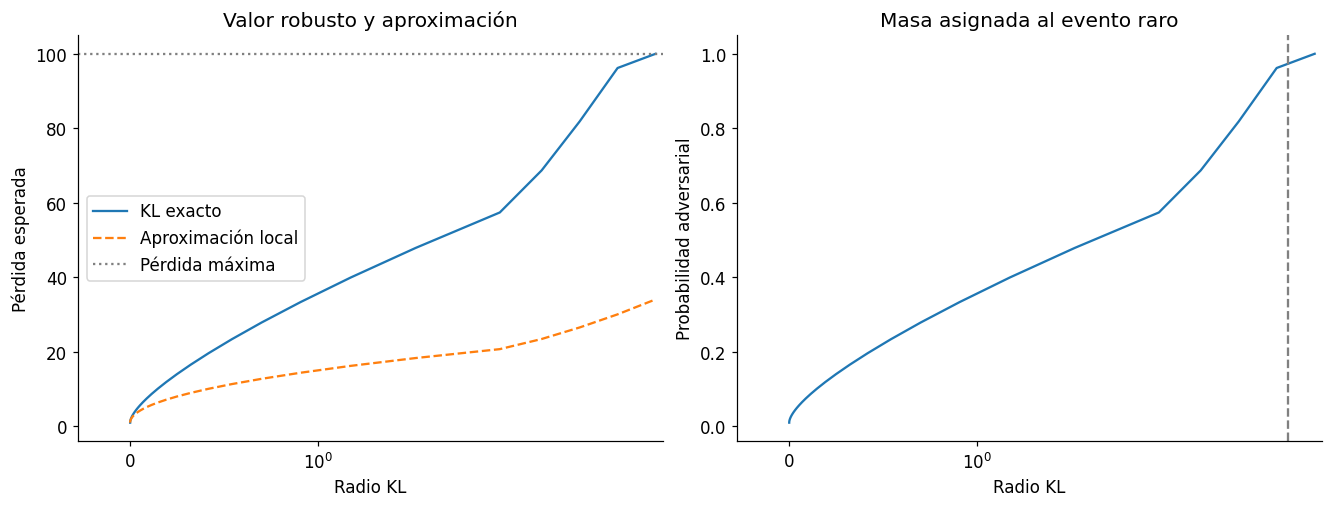

In [6]:
fig, axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
axes[0].plot(frontier.radius,frontier.robust,label='KL exacto')
axes[0].plot(frontier.radius,frontier.approximation,'--',label='Aproximación local')
axes[0].axhline(100,color='gray',linestyle=':',label='Pérdida máxima')
axes[0].set(xscale='symlog',xlabel='Radio KL',ylabel='Pérdida esperada',title='Valor robusto y aproximación')
axes[0].legend()
axes[1].plot(frontier.radius,frontier.worst_event_probability)
axes[1].axvline(critical,color='gray',linestyle='--')
axes[1].set(xscale='symlog',xlabel='Radio KL',ylabel='Probabilidad adversarial',title='Masa asignada al evento raro')
plt.show()

### 3. Umbral de decisión y precio de robustez
Comparar la acción riesgosa con una pérdida segura de 12 permite resolver el radio en que cambia la decisión minimax. Se usa una raíz sobre el valor robusto, no un radio elegido después de mirar la figura. El arrepentimiento nominal es el costo esperado bajo $p$ de adoptar la acción robusta frente a la acción nominal óptima.

In [7]:
from scipy.optimize import brentq
safe=12.
switch=brentq(lambda radius: robust_expectation(p,loss,radius).value-safe,1e-7,critical)
approx_switch=(safe-float(p@loss))**2/(2*float(p@((loss-p@loss)**2)))
print(f'Radio de cambio exacto: {switch:.6f}; aproximación: {approx_switch:.6f}')
print(f'Costo nominal de elegir seguro: {safe-float(p@loss):.2f}')
assert abs(robust_expectation(p,loss,switch).value-safe)<1e-7
checks=[]
for radius in [.001,.1,1.]:
    base=robust_expectation(p,loss,radius).value
    affine=robust_expectation(p,2*loss+7,radius).value
    checks.append(abs(affine-(2*base+7)))
assert max(checks)<1e-8
print('Error máximo de equivariancia afín positiva:',max(checks))

Radio de cambio exacto: 0.194540; aproximación: 0.611111
Costo nominal de elegir seguro: 11.00
Error máximo de equivariancia afín positiva: 1.7763568394002505e-15


### 4. Discusión metodológica
La invariancia afín positiva prueba consistencia al cambiar unidades; no prueba que el soporte sea correcto. Un evento ausente del soporte no puede recibir masa con KL(q||p) finito. El costo nominal calculado es específico de estas dos acciones, sin interpretación de capital regulatorio. Para una aplicación empírica faltan la selección del soporte, calibración del radio y evaluación temporal fuera de muestra.

### Lectura de los resultados ejecutados

El cambio minimax ocurre en **ρ = 0.194540**, mientras la aproximación local lo sitúa en **ρ = 0.611111**. La diferencia afecta qué acción se elige, además del valor de la pérdida. Elegir la acción segura cuesta **11 unidades de pérdida nominal adicional** en este ejemplo. El error máximo de equivariancia afín fue **1.78×10⁻¹⁵**; esto verifica consistencia numérica, no calibración del radio.